# 05-2. 결빙 위험도 기준표와 지도

05(결빙 위험도 산출 및 지도 가시화)의 3~6장.

05 구성: 05-1 구간별 추정·결빙 영향인자(1~2장) · **05-2 위험도 기준표·산출·지도(3~6장)**

3. 기상·도로·지형 요인별 위험 수준(1~4)과 근거를 기준표로 만든다.
4. 구간별 위험도 점수와 등급(관심·주의·경계·심각)을 산출하고 RWIS 관측과 비교한다.
5. 기존 결빙취약구간과 비교한다 (자료 확보 시).
6. 지도(jpg, png, html)와 shapefile로 저장한다.

- 입력: 02-2의 구간·지점 정보, 05-1의 구간별 추정값·노면온도 요약·결빙 가능 조건, 04-1의 결빙 분류 모델 정보(`model/icing_meta.json`)
- 출력: 위험도 지도(`figures/risk_map.jpg`·`png`·`html`, `figures/risk_map_shp/`), 기준표·구간별 위험도(`data/results/`)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import json
import warnings

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from cycler import cycler
from matplotlib import font_manager
from matplotlib.lines import Line2D
from scipy.stats import spearmanr

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#4a3aa7", "#e34948"]),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})
GRADES = ["관심", "주의", "경계", "심각"]
GRADE_COLORS = {"관심": "#0ca30c", "주의": "#fab219", "경계": "#ec835a", "심각": "#d03b3b"}
N_WINTERS = len(config.PERIODS)

In [3]:
segments = gpd.read_file(config.PROCESSED_DIR / "segments.gpkg")
seg_feat = pd.read_parquet(config.PROCESSED_DIR / "segment_features.parquet").merge(
    pd.read_parquet(config.PROCESSED_DIR / "segment_estimates.parquet"), on=["seg_id", "time"], how="left",
    validate="one_to_one")  # 05-1의 구간별 추정값 (rst_est, rst_dpd, p_icing)
seg_summary = pd.read_parquet(config.PROCESSED_DIR / "segment_summary.parquet")
stations = pd.read_parquet(config.PROCESSED_DIR / "stations.parquet").set_index("stn")
station_seg = pd.read_csv(config.PROCESSED_DIR / "station_segment_match.csv")
sf = pd.read_parquet(config.PROCESSED_DIR / "station_features.parquet").merge(
    pd.read_parquet(config.PROCESSED_DIR / "station_estimates.parquet"), on=["stn", "time"])
cls_meta = json.load(open(config.MODEL_DIR / "icing_meta.json", encoding="utf-8"))

# 05-1(2장)에서 정한 결빙 가능 환경조건
cond = json.load(open(config.PROCESSED_DIR / "icing_conditions.json", encoding="utf-8"))
T_RST, T_RH = cond["T_RST"], cond["T_RH"]
conditions = pd.DataFrame.from_dict(cond["conditions"], orient="index")
corr = pd.DataFrame(cond["station_corr"])


def icing_condition(df, rst_col="rst"):
    """결빙 가능 환경조건: 저온 + 고습 + 수분 공급 (05-1의 2장과 같은 정의)."""
    moist = (df["rain_hrs12h"] > 0) | (df["snow"] > 0) | ((df[rst_col] - df["td"]) <= 0)
    return (df[rst_col] <= T_RST) & (df["rh"] >= T_RH) & moist


print(f"구간 {len(segments)}개, 구간 시계열 {seg_feat.shape[0]:,}행 (1시간 간격)")
print(f"결빙 가능 조건: 노면온도 ≤ {T_RST}°C, 습도 ≥ {T_RH:.0f}%, 수분 공급")

구간 233개, 구간 시계열 1,342,080행 (1시간 간격)
결빙 가능 조건: 노면온도 ≤ 1.0°C, 습도 ≥ 70%, 수분 공급


## 3. 결빙 위험도 기준표

요인별 하위 지표를 1~4 수준으로 나누고, 요인 점수는 하위 지표의 평균(도로는 최댓값)으로 한다.

- **기상**: 구간별 추정값으로 계산한 동적 지표. 구간 간 상대 비교를 위해 사분위수로 수준을 나눈다.
- **도로**: 교량(상판 아래로 열이 빠져 노면이 빨리 식는다), 터널 입출구(터널 안팎 온도·햇빛 차이, 그늘).
- **지형**: 표고(기온감률), 겨울 지형 그늘(일사 차단), 하천 인접·골짜기(습도, 찬 공기 고임).

요인별 이론 근거 (01-1의 0장, 01-6·01-7의 13장)

| 요인 | 이론 | 이 자료에서 확인한 것 |
|------|------|------------------------|
| 교량 | 교량 노면은 일반 도로보다 1~2°C 낮다 (Tabatabai & Aljuboori 2017; Rathke & McPherson 2006). 모든 교량이 그렇지는 않다 (김유정 외 2023) | 우곡3교는 밤 -1.6°C, 부곡교는 +0.6°C. 지점마다 다름 (13-7) |
| 터널 입출구 | 입·출구 부근 노면온도 급변 (김유정 외 2023), 터널 입구는 블랙아이스 취약 장소 (Hong et al. 2022) | 고정 관측소 1곳뿐이라 확인 불가 (13-8) |
| 표고 | 기온감률 약 6.5°C/km, 대기 안정도에 따라 0~9°C/km (Chapman et al. 2001) | 산 정상을 뺀 AWS 밤 감률 0.73~0.82°C/100m로 안정도와 거의 무관 (13-5) |
| 지형 그늘 | 차폐가 낮 동안 노면 가열을 줄인다 (Chapman et al. 2001) | 겨울 지형 그늘과 맑은 한낮 노면 편차 순위상관 -0.38 (13-6) |
| 하천·골짜기 | 골짜기 바닥의 찬 공기 고임(냉기호), 안개·수증기 응결 (Chapman et al. 2001; Zerr 1997) | 안정한 밤일수록 표고로 설명되지 않는 지점 차가 커짐 (13-5) |

교량·터널 효과는 지점마다 달라서 도로 요인에 총점의 1/4만 주고, 기상 요인에 절반을 준다. 곡률·경사는 결빙 발생이 아니라 사고 위험 요인이므로
기상학적 결빙 위험도에는 넣지 않는다.

총점 = 0.5 x 기상 + 0.25 x 도로 + 0.25 x 지형 (1~4점). 기상은 결빙의 직접 원인이라 절반을 주고,
도로·지형은 같은 날씨에서 위험을 키우는 요인으로 나누어 준다. 가중치는 4장에서 민감도를 확인한다.

In [4]:
seg = segments.set_index("seg_id").join(seg_summary)
seg["icing_cond_hours"] = (seg_feat.assign(c=icing_condition(seg_feat, rst_col="rst_est"))
                           .groupby("seg_id")["c"].sum() / N_WINTERS)
seg["icing_pred_hours"] = (seg_feat.assign(c=seg_feat["p_icing"] >= cls_meta["threshold"])
                           .groupby("seg_id")["c"].sum() / N_WINTERS)
seg["tunnel_portal"] = (seg["seg_dist_tunnel"] <= 300) & (seg["tunnel_ratio"] < 0.9)


def quartile_level(x):
    q = x.quantile([0.25, 0.5, 0.75]).to_numpy()
    return pd.Series(np.digitize(x, q, right=True) + 1, index=x.index), q


def cut_level(x, bins):
    return pd.Series(np.digitize(x, bins, right=False) + 1, index=x.index).clip(1, 4)


lv = pd.DataFrame(index=seg.index)
lv["M1"], q_m1 = quartile_level(seg["icing_cond_hours"])
lv["M2"], q_m2 = quartile_level(seg["icing_pred_hours"])
lv["R1"] = cut_level(seg["bridge_ratio"], [1e-9, 0.1, 0.3])
lv["R2"] = np.select([seg["tunnel_ratio"] >= 0.9, seg["tunnel_portal"], seg["seg_dist_tunnel"] <= 1000], [1, 3, 2], 1)
lv["T1"] = cut_level(seg["elev"], [100, 250, 400])
lv["T2"] = cut_level(seg["shade_winter"], [0.02, 0.05, 0.10])
lv["T3"] = np.select([(seg["dist_river"] <= 100) | (seg["tpi"] <= -30),
                      (seg["dist_river"] <= 300) | (seg["tpi"] <= -10)], [3, 2], 1)

criteria = pd.DataFrame([
    ["기상", "M1 결빙 가능 시간 (h/겨울)", f"≤{q_m1[0]:.0f}", f"{q_m1[0]:.0f}~{q_m1[1]:.0f}", f"{q_m1[1]:.0f}~{q_m1[2]:.0f}",
     f">{q_m1[2]:.0f}",
     f"추정 노면온도 ≤ {T_RST}°C, 습도 ≥ {T_RH:.0f}%, 수분 공급(강수·적설·서리)인 시간. "
     f"학습 지점 Ice의 {conditions.iloc[-1]['Ice 포착률']:.0%}를 포함하고 평균 대비 {conditions.iloc[-1]['향상도(lift)']:.1f}배. "
     "결빙 = 수분 + 어는점 이하 노면 (Zerr 1997), 강수 시 노면 1°C 미만 결빙 (Bonanno et al. 2010)"],
    ["기상", "M2 결빙관련 노면 예측 시간 (h/겨울)", f"≤{q_m2[0]:.0f}", f"{q_m2[0]:.0f}~{q_m2[1]:.0f}",
     f"{q_m2[1]:.0f}~{q_m2[2]:.0f}", f">{q_m2[2]:.0f}",
     f"04 분류 모델 확률 ≥ {cls_meta['threshold']:.2f}인 시간 (Snow·Ice·결빙시작·판별불가 노면)"],
    ["도로", "R1 교량 구간 비율", "0", "0~10%", "10~30%", ">30%",
     "교량 상판은 위아래로 공기에 노출되어 노면이 빨리 식는다. 교량 노면은 일반 도로보다 1~2°C 낮다 "
     "(Tabatabai & Aljuboori 2017; Rathke & McPherson 2006). 관측소에서도 교량에 가까울수록 노면 0°C 이하 비율이 높다. "
     "단 교량마다 차이가 커서(우곡3교 -1.6°C, 부곡교 +0.6°C) 도로 요인 안에서만 반영한다"],
    ["도로", "R2 터널 입출구", "터널 안(90% 이상)·해당 없음", "터널 1km 이내", "입출구 300m 이내", "-",
     "터널 입출구는 그늘이 지고 터널 안팎의 온도·노면 습윤 차이가 커서 결빙이 잦다. "
     "입·출구 부근 노면온도 급변 (김유정 외 2023), 터널 입구는 블랙아이스 취약 장소 (Hong et al. 2022)"],
    ["지형", "T1 표고", "<100m", "100~250m", "250~400m", "≥400m",
     f"기온감률(약 0.65°C/100m, Chapman et al. 2001). 관측소 노면 0°C 이하 비율과 순위상관 {corr.loc['표고', '노면0도이하비율']:.2f}"],
    ["지형", "T2 겨울 지형 그늘 비율", "<2%", "2~5%", "5~10%", "≥10%",
     f"동지 무렵 직달 일사 중 산에 가려지는 비율. 차폐가 낮 동안 노면 가열을 줄인다 (Chapman et al. 2001). "
     f"노면 0°C 이하 비율과 순위상관 {corr.loc['겨울 지형 그늘', '노면0도이하비율']:.2f}"],
    ["지형", "T3 하천 인접·골짜기", "해당 없음", "하천 300m 이내 또는 TPI ≤ -10m", "하천 100m 이내 또는 TPI ≤ -30m", "-",
     "하천 주변은 습도가 높고 안개가 잦으며(수증기 응결, Zerr 1997), 골짜기는 밤에 찬 공기가 고인다 (냉기호, Chapman et al. 2001)"],
], columns=["요인", "지표", "수준1", "수준2", "수준3", "수준4", "기준 설정 근거"])
criteria

,요인,지표,수준1,수준2,수준3,수준4,기준 설정 근거
0,기상,M1 결빙 가능 시간 (h/겨울),≤260,260~288,288~342,>342,"추정 노면온도 ≤ 1.0°C, 습도 ≥ 70%, 수분 공급(강수·적설·서리)인 시간..."
1,기상,M2 결빙관련 노면 예측 시간 (h/겨울),≤9,9~13,13~20,>20,04 분류 모델 확률 ≥ 0.85인 시간 (Snow·Ice·결빙시작·판별불가 노면)
2,도로,R1 교량 구간 비율,0,0~10%,10~30%,>30%,교량 상판은 위아래로 공기에 노출되어 노면이 빨리 식는다. 교량 노면은 일반 도로보...
3,도로,R2 터널 입출구,터널 안(90% 이상)·해당 없음,터널 1km 이내,입출구 300m 이내,-,터널 입출구는 그늘이 지고 터널 안팎의 온도·노면 습윤 차이가 커서 결빙이 잦다. ...
4,지형,T1 표고,<100m,100~250m,250~400m,≥400m,"기온감률(약 0.65°C/100m, Chapman et al. 2001). 관측소 ..."
5,지형,T2 겨울 지형 그늘 비율,<2%,2~5%,5~10%,≥10%,동지 무렵 직달 일사 중 산에 가려지는 비율. 차폐가 낮 동안 노면 가열을 줄인다 ...
6,지형,T3 하천 인접·골짜기,해당 없음,하천 300m 이내 또는 TPI ≤ -10m,하천 100m 이내 또는 TPI ≤ -30m,-,"하천 주변은 습도가 높고 안개가 잦으며(수증기 응결, Zerr 1997), 골짜기는..."


In [5]:
WEIGHTS = {"기상": 0.5, "도로": 0.25, "지형": 0.25}


def score_segments(levels, weights=WEIGHTS):
    """구간별 요인 점수, 총점(1~4), 등급."""
    out = pd.DataFrame(index=levels.index)
    out["기상"] = levels[["M1", "M2"]].mean(axis=1)
    out["도로"] = levels[["R1", "R2"]].max(axis=1)
    out["지형"] = levels[["T1", "T2", "T3"]].mean(axis=1)
    out["총점"] = sum(out[k] * w for k, w in weights.items())
    out["등급"] = pd.cut(out["총점"], [0, 1.75, 2.5, 3.25, 4.01], labels=GRADES, right=False)
    return out


grade_table = pd.DataFrame({"총점 범위": ["1.00~1.75", "1.75~2.50", "2.50~3.25", "3.25~4.00"],
                            "의미": ["평상시 관리", "결빙 가능 기상 시 순찰 강화", "사전 제설·제빙 우선 구간",
                                   "상시 감시·사전 살포 최우선 구간"]}, index=GRADES)
grade_table

,총점 범위,의미
관심,1.00~1.75,평상시 관리
주의,1.75~2.50,결빙 가능 기상 시 순찰 강화
경계,2.50~3.25,사전 제설·제빙 우선 구간
심각,3.25~4.00,상시 감시·사전 살포 최우선 구간


## 4. 구간별 위험도 산출

In [6]:
scores = score_segments(lv)
seg = seg.join(lv).join(scores)
print(seg["등급"].value_counts().reindex(GRADES).to_string())
pd.crosstab(seg["route"], seg["등급"]).reindex(columns=GRADES)

등급
관심     58
주의    105
경계     51
심각     19


등급,관심,주의,경계,심각
route,,,,
서해안,17,75,8,0
통영-대전중부선,0,4,25,18
호남선,41,26,18,1


In [7]:
top = seg.sort_values("총점", ascending=False).head(15)
top[["route", "elev", "bridge_ratio", "shade_winter", "icing_cond_hours", "icing_pred_hours",
     "기상", "도로", "지형", "총점", "등급"]].round(2)

,route,elev,bridge_ratio,shade_winter,icing_cond_hours,icing_pred_hours,기상,도로,지형,총점,등급
seg_id,,,,,,,,,,,
TD-004,통영-대전중부선,445.630005,0.41,0.13,501.0,21.5,4.0,4,3.33,3.83,심각
TD-014,통영-대전중부선,483.940002,0.35,0.06,505.5,24.5,4.0,4,3.33,3.83,심각
TD-024,통영-대전중부선,403.290009,0.86,0.03,529.0,22.0,4.0,4,3.00,3.75,심각
TD-002,통영-대전중부선,483.940002,0.27,0.11,524.5,21.5,4.0,3,3.67,3.67,심각
TD-015,통영-대전중부선,494.029999,0.34,0.03,522.0,23.5,4.0,4,2.67,3.67,심각
TD-011,통영-대전중부선,461.760010,0.38,0.02,498.0,25.0,4.0,4,2.33,3.58,심각
TD-003,통영-대전중부선,576.700012,0.21,0.15,574.0,25.5,4.0,3,3.00,3.50,심각
HN-001,호남선,135.100006,0.00,0.15,396.0,45.5,4.0,3,3.00,3.50,심각
TD-009,통영-대전중부선,440.589996,0.00,0.04,487.0,21.5,4.0,3,3.00,3.50,심각


**RWIS 관측과 비교**: 관측소가 있는 구간의 위험도 총점과, 그 관측소에서 실제로 관측된 결빙 관련 지표를 비교한다.
검증 지점 3곳도 포함한다 (관측소는 17곳뿐이므로 참고용).

In [8]:
all_stats = sf[sf["ice"].notna()].groupby("stn").agg(
    Ice비율=("ice", "mean"),
    결빙관련비율=("state", lambda s: s.isin(cls_meta["label_states"]).mean()),
    노면0도이하비율=("rst", lambda s: (s <= 0).mean()))
val = station_seg.set_index("stn")[["name", "seg_id", "holdout"]].join(all_stats)
val = val.join(seg[["기상", "도로", "지형", "총점", "등급"]], on="seg_id")
print({t: round(spearmanr(val["총점"], val[t])[0], 2) for t in ["Ice비율", "결빙관련비율", "노면0도이하비율"]})
val.sort_values("총점", ascending=False).round(4)

{'Ice비율': np.float64(-0.07), '결빙관련비율': np.float64(-0.12), '노면0도이하비율': np.float64(0.7)}


,name,seg_id,holdout,Ice비율,결빙관련비율,노면0도이하비율,기상,도로,지형,총점,등급
stn,,,,,,,,,,,
33411,삼봉(도),TD-004,True,0.0000,0.0074,0.3733,4.0,4,3.3333,3.8333,심각
33412,대곡(도),TD-002,False,0.0000,0.0116,0.3671,4.0,3,3.6667,3.6667,심각
23403,호남터널(도),HN-001,False,0.0014,0.0222,0.2553,4.0,3,3.0000,3.5000,심각
33410,삼가2교(도),TD-027,False,0.0000,0.0118,0.3567,3.5,3,3.6667,3.4167,심각
33103,덕유산휴(도),TD-017,False,0.0003,0.0096,0.3482,4.0,1,3.3333,3.0833,경계
33409,가당2교(도),TD-046,False,0.0000,0.0044,0.3317,2.5,2,2.6667,2.4167,주의
33206,용포1교(도),TD-041,False,0.0008,0.0133,0.2990,3.0,2,1.6667,2.4167,주의
12409,우곡3교(도),SH-091,False,0.0002,0.0063,0.3174,2.5,3,1.3333,2.3333,주의
12209,서김제(도),SH-070,False,0.0005,0.0137,0.3086,3.0,2,1.0000,2.2500,주의


- 총점은 관측소의 **노면 0°C 이하 비율과 순위상관이 높다**(0.70). 노면이 얼 만큼 차가워지는 저온 노출은 잘 반영한다.
- **Ice·결빙관련 비율과는 상관이 거의 없다.** 관측된 Ice는 서해안선 일부 관측소(부안고려청자휴 등)에 몰려 있고,
  서해안선 관측소만 제빙제 관련 코드(12·13)를 쓰는 등 관측소마다 센서 판정 특성이 다른 것으로 보인다.
  Ice 빈도까지 맞추려면 강수·적설 빈도의 비중을 키우거나 센서 특성을 보정하는 방안을 검토해야 한다.

가중치 민감도: 요인 가중치를 바꾸었을 때 등급이 바뀌는 구간 비율

In [9]:
sens = {}
for name, w in {"균등 (1/3씩)": {"기상": 1 / 3, "도로": 1 / 3, "지형": 1 / 3},
                "기상 중심 (0.7/0.15/0.15)": {"기상": 0.7, "도로": 0.15, "지형": 0.15},
                "구조 중심 (0.4/0.3/0.3)": {"기상": 0.4, "도로": 0.3, "지형": 0.3}}.items():
    alt = score_segments(lv, w)
    sens[name] = {"등급 변경 구간 비율": (alt["등급"] != seg["등급"]).mean(),
                  "총점 순위상관": spearmanr(alt["총점"], seg["총점"])[0],
                  **alt["등급"].value_counts().reindex(GRADES).to_dict()}
pd.DataFrame(sens).T.round(3)

,등급 변경 구간 비율,총점 순위상관,관심,주의,경계,심각
균등 (1/3씩),0.232,0.965,79.0,102.0,40.0,12.0
기상 중심 (0.7/0.15/0.15),0.176,0.972,64.0,85.0,52.0,32.0
구조 중심 (0.4/0.3/0.3),0.150,0.990,76.0,92.0,50.0,15.0


## 5. 기존 결빙취약구간(22개소)과 비교

전북도 고속도로 기존 결빙취약구간 22개소는 제공 데이터에 없다. 자료를 확보하면 아래 형식으로
`data/external/vulnerable_sections.csv`에 두고 이 셀을 다시 실행한다 (출처·이용조건은 README에 기재).

| 컬럼 | 내용 |
|------|------|
| `name` | 구간명 |
| `route` | 노선명 (서해안, 호남선, 통영-대전중부선) |
| `lat`, `lon` | 구간 대표 위경도 (WGS84) |

In [10]:
def compare_with_vulnerable_sections(scored, vulnerable, max_dist_m=500):
    """기존 결빙취약구간과 산출 결과를 비교한다."""
    pts = gpd.GeoDataFrame(vulnerable, geometry=gpd.points_from_xy(vulnerable["lon"], vulnerable["lat"]),
                           crs=4326).to_crs(scored.crs)
    idx, dist = scored.sindex.nearest(pts.geometry, return_distance=True, return_all=False)
    pts["seg_id"] = scored.index.to_numpy()[idx[1]]
    pts["dist_m"] = dist.round(0)
    pts = pts.join(scored[["총점", "등급"]], on="seg_id")
    pts.loc[pts["dist_m"] > max_dist_m, ["seg_id", "총점", "등급"]] = np.nan
    return pts.drop(columns="geometry")


vuln_path = config.DATA_DIR / "external" / "vulnerable_sections.csv"
vuln_cmp = None
if vuln_path.exists():
    vuln_cmp = compare_with_vulnerable_sections(seg, pd.read_csv(vuln_path, encoding="utf-8-sig"))
    hit = vuln_cmp["등급"].isin(["경계", "심각"]).mean()
    print(f"취약구간 {len(vuln_cmp)}곳 중 경계·심각 등급 구간에 해당: {hit:.0%}")
    print("전체 구간 중 경계·심각 비율:", f"{seg['등급'].isin(['경계', '심각']).mean():.0%}")
    display(vuln_cmp)
else:
    print(f"{vuln_path.relative_to(ROOT)} 가 없어 비교를 건너뜀")

data/external/vulnerable_sections.csv 가 없어 비교를 건너뜀


## 6. 지도 가시화 및 저장
jpg, shapefile

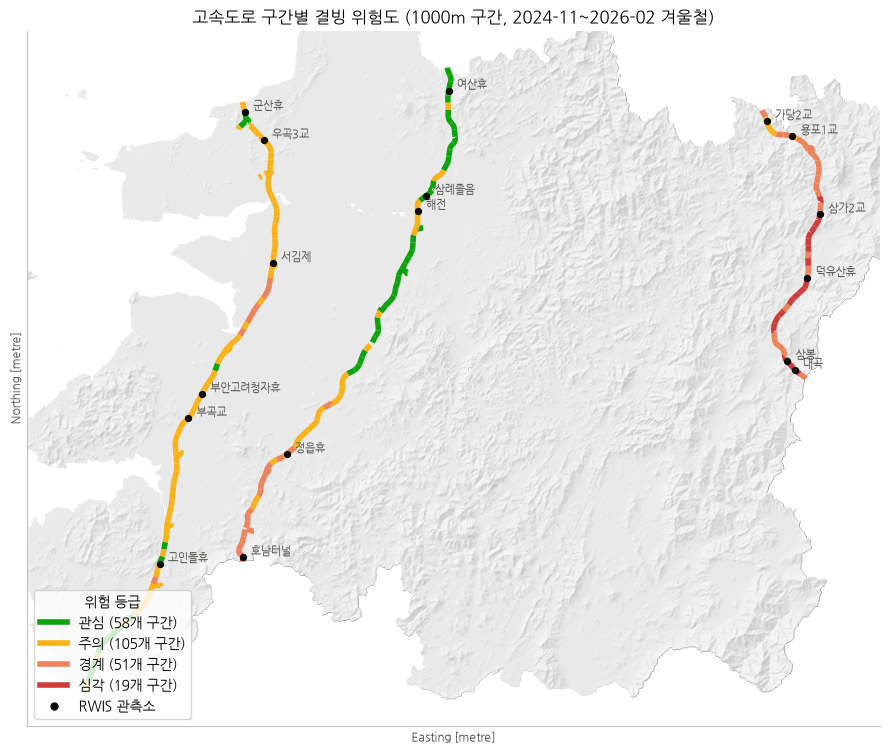

In [11]:
with rasterio.open(config.RAW_DIR / config.RAW_FILES["dem"]) as src:
    step = 4
    dem = src.read(1, out_shape=(src.height // step, src.width // step)).astype(float)
    b = src.bounds
dem[dem < -1000] = np.nan
dem_scale = json.load(open(config.PROCESSED_DIR / "features.json", encoding="utf-8"))["dem_scale"]
gy, gx = np.gradient(np.nan_to_num(dem, nan=0.0) * dem_scale, 30 * step)  # 정규화 DEM → m (02 참고)
slope = np.arctan(np.hypot(gx, gy))
aspect = np.arctan2(-gx, gy)
az, alt = np.radians(315), np.radians(45)
hillshade = np.sin(alt) * np.cos(slope) + np.cos(alt) * np.sin(slope) * np.cos(az - aspect)
hillshade[np.isnan(dem)] = np.nan


def plot_risk_map(scored, path=None, title="고속도로 구간별 결빙 위험도"):
    """구간별 결빙 위험도 지도 (jpg/png)."""
    fig, ax = plt.subplots(figsize=(11, 11))
    ax.imshow(hillshade, extent=[b.left, b.right, b.bottom, b.top], cmap="Greys_r", vmin=-0.2, vmax=1.2, alpha=0.35)
    for grade in GRADES:
        part = scored[scored["등급"] == grade]
        if len(part):
            part.plot(ax=ax, color=GRADE_COLORS[grade], linewidth=4)
    st = gpd.GeoDataFrame(stations, geometry=gpd.points_from_xy(stations["lon"], stations["lat"]), crs=4326)
    st = st.to_crs(scored.crs)
    st.plot(ax=ax, color="#0b0b0b", markersize=18, marker="o", zorder=5)
    for stn, r in st.iterrows():
        ax.annotate(r["name"].replace("(도)", ""), (r.geometry.x, r.geometry.y), xytext=(6, 2),
                    textcoords="offset points", fontsize=8, color="#52514e")
    counts = scored["등급"].value_counts()
    handles = [Line2D([0], [0], color=GRADE_COLORS[g], linewidth=4, label=f"{g} ({counts.get(g, 0)}개 구간)")
               for g in GRADES]
    handles.append(Line2D([0], [0], color="#0b0b0b", marker="o", linestyle="", markersize=5, label="RWIS 관측소"))
    ax.legend(handles=handles, loc="lower left", title="위험 등급", frameon=True)
    xmin, ymin, xmax, ymax = scored.total_bounds
    ax.set_xlim(xmin - 8000, xmax + 8000)
    ax.set_ylim(ymin - 5000, ymax + 5000)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"{title} ({config.SEGMENT_LENGTH_M}m 구간, {config.PERIODS[0][0][:7]}~{config.PERIODS[-1][1][:7]} 겨울철)")
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    return fig, ax


fig, ax = plot_risk_map(seg, path=config.FIGURE_DIR / "risk_map.jpg")
fig.savefig(config.FIGURE_DIR / "risk_map.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

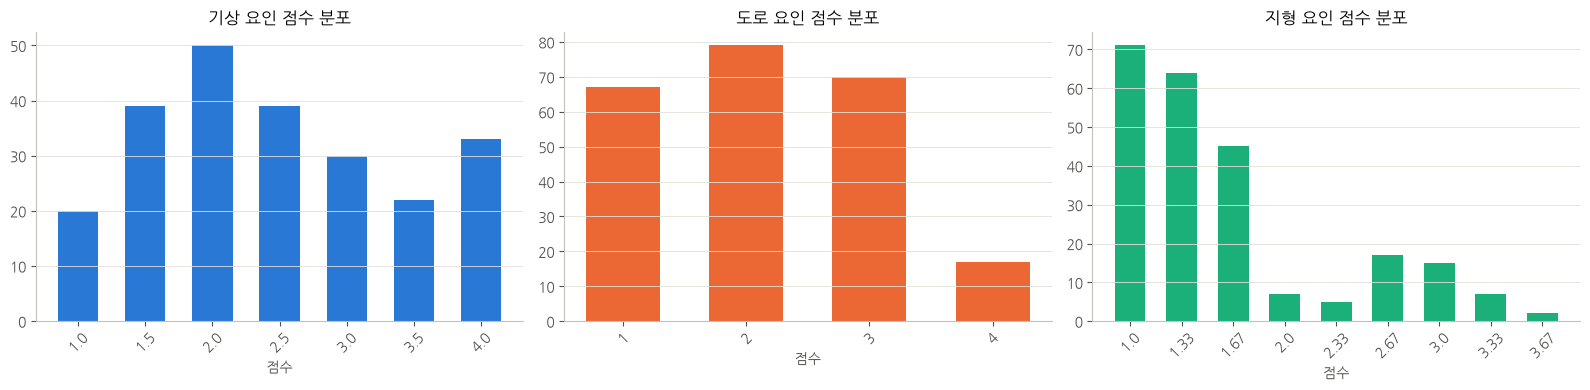

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, factor, color in zip(axes, ["기상", "도로", "지형"], ["#2a78d6", "#eb6834", "#1baf7a"]):
    vals = seg[factor].round(2).value_counts().sort_index()
    ax.bar(vals.index.astype(str), vals.values, color=color, width=0.6)
    ax.set_title(f"{factor} 요인 점수 분포")
    ax.set_xlabel("점수")
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [13]:
def export_risk_shapefile(scored, path):
    """구간별 결빙 위험도를 shapefile로 내보낸다 (컬럼명 10자 이내)."""
    out = scored.reset_index()[["seg_id", "route", "length_m", "elev", "bridge_ratio", "shade_winter",
                                "icing_cond_hours", "icing_pred_hours", "rst_night_mean",
                                "기상", "도로", "지형", "총점", "등급", "geometry"]]
    out = out.rename(columns={"length_m": "length", "bridge_ratio": "bridge_r", "shade_winter": "shade",
                              "icing_cond_hours": "cond_h", "icing_pred_hours": "pred_h",
                              "rst_night_mean": "rst_night", "기상": "s_meteo", "도로": "s_road",
                              "지형": "s_terrain", "총점": "score", "등급": "grade"})
    out["grade"] = out["grade"].astype(str)
    out["grade_lv"] = out["grade"].map({g: i + 1 for i, g in enumerate(GRADES)})
    out = gpd.GeoDataFrame(out.round(3), geometry="geometry", crs=scored.crs)
    path.parent.mkdir(parents=True, exist_ok=True)
    out.to_file(path, driver="ESRI Shapefile", encoding="utf-8")
    return out


shp = export_risk_shapefile(seg, config.FIGURE_DIR / "risk_map_shp" / "segment_risk.shp")
print(shp.shape, sorted(p.name for p in (config.FIGURE_DIR / "risk_map_shp").iterdir()))

(233, 16) ['segment_risk.cpg', 'segment_risk.dbf', 'segment_risk.prj', 'segment_risk.shp', 'segment_risk.shx']


확대·이동이 가능한 웹 지도(html)도 만든다. 구간을 누르면 요인별 점수를 볼 수 있다.

In [14]:
web = seg.reset_index().to_crs(4326)
web["등급"] = web["등급"].astype(str)
fmap = folium.Map(location=[35.78, 127.1], zoom_start=9, tiles="CartoDB positron")
folium.GeoJson(
    web[["seg_id", "route", "등급", "총점", "기상", "도로", "지형", "elev", "bridge_ratio", "geometry"]].round(2),
    style_function=lambda f: {"color": GRADE_COLORS[f["properties"]["등급"]], "weight": 6, "opacity": 0.9},
    tooltip=folium.GeoJsonTooltip(fields=["seg_id", "route", "등급", "총점", "기상", "도로", "지형", "elev", "bridge_ratio"],
                                  aliases=["구간", "노선", "등급", "총점", "기상", "도로", "지형", "표고(m)", "교량 비율"]),
).add_to(fmap)
legend = "".join(f"<div><span style='display:inline-block;width:14px;height:6px;background:{GRADE_COLORS[g]};"
                 f"margin-right:6px'></span>{g}</div>" for g in GRADES)
fmap.get_root().html.add_child(folium.Element(
    f"<div style='position:fixed;bottom:24px;left:24px;z-index:9999;background:white;padding:8px 10px;"
    f"border:1px solid #c3c2b7;font-size:13px'><b>결빙 위험 등급</b>{legend}</div>"))
fmap.save(config.FIGURE_DIR / "risk_map.html")

결과 CSV 저장

In [15]:
criteria.to_csv(config.RESULT_DIR / "risk_criteria.csv", index=False, encoding="utf-8-sig")
(seg.drop(columns="geometry").reset_index()
 [["seg_id", "route", "length_m", "lon", "lat", "elev", "tpi", "shade_winter", "dist_river", "bridge_ratio",
   "tunnel_ratio", "seg_dist_tunnel", "rst_mean", "rst_night_mean", "rst_le0_hours", "icing_cond_hours",
   "icing_pred_hours", "M1", "M2", "R1", "R2", "T1", "T2", "T3", "기상", "도로", "지형", "총점", "등급"]]
 .round(3).to_csv(config.RESULT_DIR / "segment_risk.csv", index=False, encoding="utf-8-sig"))
seg_feat[["seg_id", "time", "rst_est", "p_icing"]].round(3).to_parquet(
    config.RESULT_DIR / "segment_estimates_hourly.parquet", index=False)
for p in sorted(config.RESULT_DIR.iterdir()):
    print(f"{p.name:36s} {p.stat().st_size / 1e3:9.1f} KB")

estimation_cv_scores.csv                   7.3 KB
estimation_ensembles.csv                   0.4 KB
estimation_holdout_10min.csv            3718.9 KB
estimation_mlp_architectures.csv           1.3 KB
estimation_model_comparison.csv            1.2 KB
estimation_scores.csv                      1.9 KB
estimation_site_correction.csv             2.9 KB
icing_10min_scores.csv                     0.2 KB
icing_conditions.csv                       0.2 KB
icing_cv_scores.csv                        0.5 KB
icing_daily_scores.csv                    32.9 KB
icing_ensembles.csv                        0.6 KB
icing_factors.csv                          1.0 KB
icing_feature_importance.csv               1.7 KB
icing_holdout_10min.csv                 3986.2 KB
icing_mlp_architectures.csv                0.7 KB
icing_model_comparison.csv                 0.8 KB
icing_scores.csv                           4.7 KB
risk_criteria.csv                          2.1 KB
segment_estimates_hourly.parquet        5808.4 KB
